In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets
train = pd.read_csv("../data/train-test.csv")
validation = pd.read_csv("../data/validation.csv")
december = pd.read_csv("../data/december-chart-inputs.csv")

print("Training shape:", train.shape)
print("Validation shape:", validation.shape)
print("December shape:", december.shape)

Training shape: (48000, 14)
Validation shape: (12000, 13)
December shape: (31, 7)


In [5]:
# First 5 records
display(train.head())

# Last 5 records
display(train.tail())

# Column names
print(train.columns.tolist())

# Data types
print(train.dtypes)

# Dataset information
train.info()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
47995,TR-047996,Reno,Baton Rouge,39.54838,-118.64843,30.50134,-92.65374,1830.9,Flatbed,31786.0,2025-10-31,0.98865,2.05626,3787.32
47996,TR-047997,Greensboro,Memphis,35.98195,-82.78379,35.56802,-89.52871,445.8,Reefer,37465.0,2025-10-31,1.03034,1.51985,1171.93
47997,TR-047998,Greensboro,Cincinnati,35.98195,-82.78379,37.15706,-86.77499,267.9,Flatbed,24528.0,2025-10-31,1.00846,1.46954,713.36
47998,TR-047999,Memphis,Reno,35.56802,-89.52871,39.54838,-118.64843,1901.3,Flatbed,37581.0,2025-10-31,1.00014,2.05132,3987.46
47999,TR-048000,Bakersfield,Baltimore,33.28832,-116.67935,38.16908,-72.74564,2860.4,Dry Van,28359.0,2025-10-31,1.07073,2.31578,5264.84


['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal', 'posted_rate']
load_id          object
pickup           object
delivery         object
pickup_lat      float64
pickup_lon      float64
delivery_lat    float64
delivery_lon    float64
distance        float64
equipment        object
weight          float64
date             object
market_index    float64
quote_signal    float64
posted_rate     float64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery

In [6]:
missing = pd.DataFrame({
    "Missing_Count": train.isnull().sum(),
    "Missing_Percentage": train.isnull().mean() * 100
})

display(missing[missing["Missing_Count"] > 0])

,Missing_Count,Missing_Percentage
weight,300,0.625000
market_index,374,0.779167


In [7]:
display(train.describe().T)

,count,mean,std,min,25%,50%,75%,max
pickup_lat,48000.0,35.647545,4.315285,28.35765,31.98691,35.29479,39.411040,44.30296
pickup_lon,48000.0,-90.928964,13.482431,-121.69849,-98.40059,-88.08915,-83.285060,-69.50000
delivery_lat,48000.0,35.641175,4.317199,28.35765,31.98691,35.29479,39.411040,44.30296
delivery_lon,48000.0,-90.857310,13.476589,-121.69849,-98.40059,-87.52871,-83.285060,-69.50000
distance,48000.0,1135.856654,728.564416,70.00000,550.40000,953.30000,1645.525000,3439.80000
weight,47700.0,31028.844004,9391.440620,-47500.00000,25800.00000,31436.50000,37018.000000,47500.00000
market_index,47626.0,1.083387,0.168091,0.67639,0.94967,1.05580,1.219590,1.46778
quote_signal,48000.0,2.062468,0.291391,0.69228,1.89103,2.05575,2.221685,3.61035
posted_rate,48000.0,2373.980682,1486.493245,57.22000,1251.55500,2030.76000,3330.750000,25533.00000


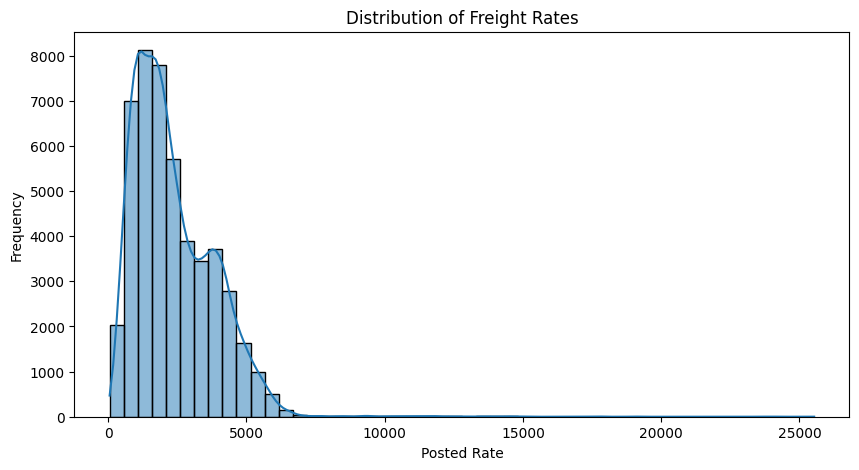

In [8]:
plt.figure(figsize=(10, 5))

sns.histplot(
    train["posted_rate"],
    bins=50,
    kde=True
)

plt.title("Distribution of Freight Rates")
plt.xlabel("Posted Rate")
plt.ylabel("Frequency")
plt.show()

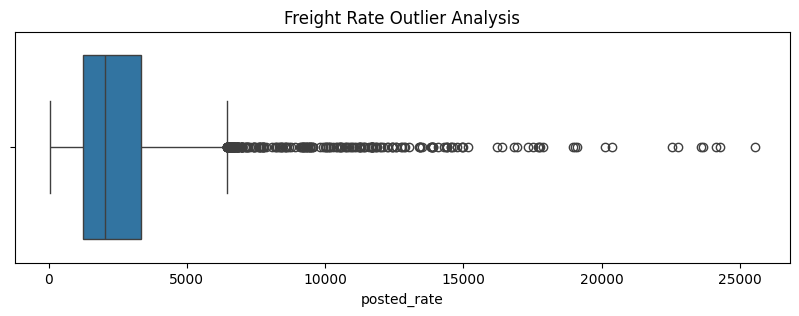

In [9]:
plt.figure(figsize=(10, 3))

sns.boxplot(x=train["posted_rate"])

plt.title("Freight Rate Outlier Analysis")
plt.show()

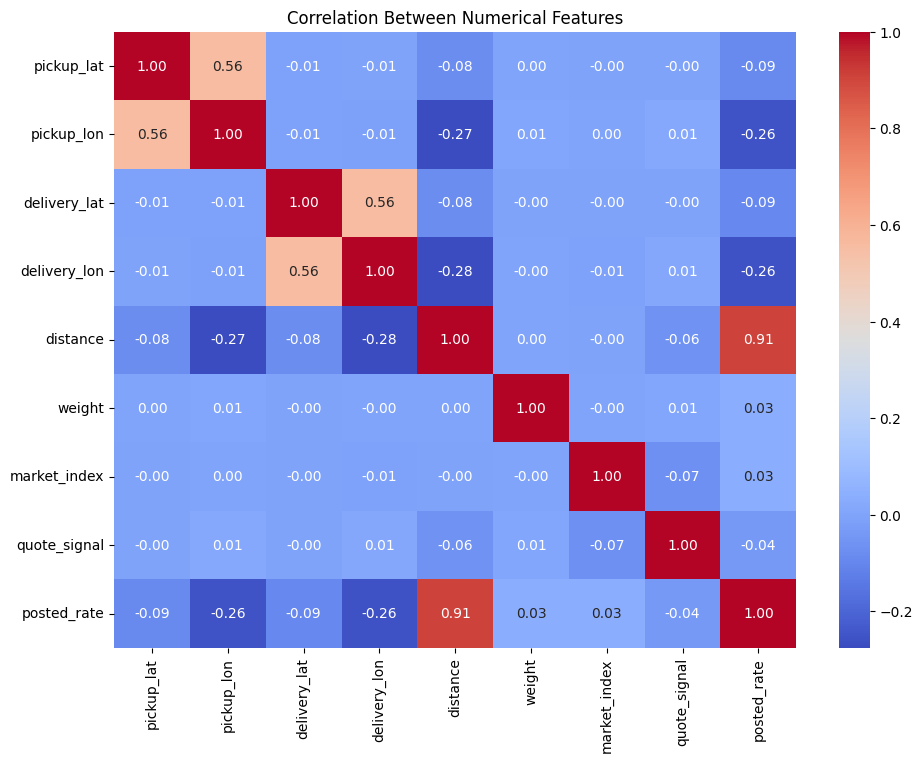

In [10]:
numeric_cols = [
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",
    "distance",
    "weight",
    "market_index",
    "quote_signal",
    "posted_rate"
]

correlation = train[numeric_cols].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Features")
plt.show()

In [11]:
equipment_analysis = (
    train.groupby("equipment")["posted_rate"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(equipment_analysis)

,count,mean,median,std
equipment,,,,
Dry Van,27202,2271.55,1953.04,1423.03
Flatbed,8753,2445.09,2076.81,1505.05
Reefer,12045,2553.64,2196.67,1589.67


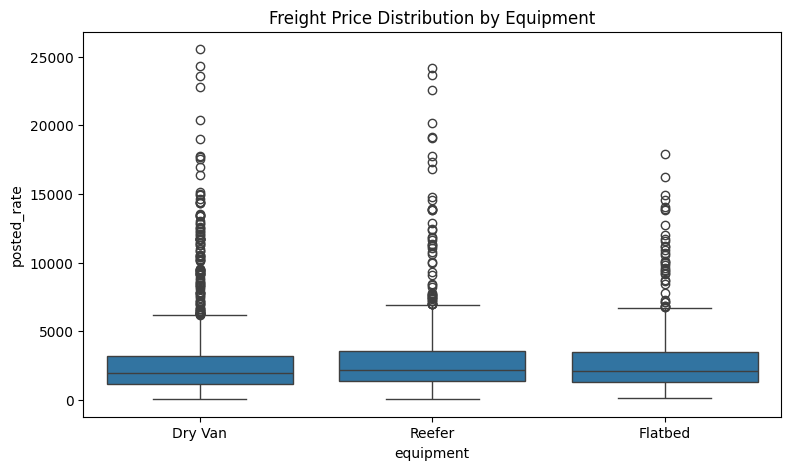

In [12]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=train,
    x="equipment",
    y="posted_rate"
)

plt.title("Freight Price Distribution by Equipment")
plt.show()

,mean,median,count
date,,,
1,2255.967048,1915.200,4918
2,2273.804801,1994.250,4337
3,2372.268092,2022.920,5036
4,2372.162308,2044.240,4819
5,2421.776342,2065.510,4913
6,2497.030115,2120.220,4783
7,2415.162030,2059.145,4912
8,2338.407661,2015.730,4759
9,2406.374013,2057.130,4670


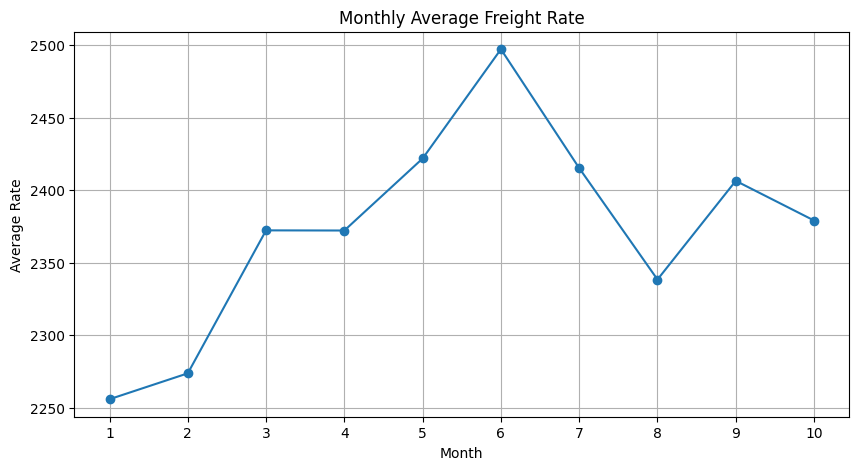

In [13]:
train["date"] = pd.to_datetime(train["date"])

monthly = (
    train.groupby(train["date"].dt.month)
    ["posted_rate"]
    .agg(["mean", "median", "count"])
)

display(monthly)

monthly["mean"].plot(
    figsize=(10, 5),
    marker="o"
)

plt.title("Monthly Average Freight Rate")
plt.xlabel("Month")
plt.ylabel("Average Rate")
plt.xticks(range(1, 11))
plt.grid()
plt.show()

In [14]:
negative_weights = train[train["weight"] < 0]

print("Negative weight records:",
      len(negative_weights))

display(
    negative_weights[
        ["pickup", "delivery", "distance",
         "equipment", "weight", "posted_rate"]
    ].head(20)
)

Negative weight records: 292


,pickup,delivery,distance,equipment,weight,posted_rate
68,Amarillo,Dayton,1334.2,Reefer,-36559.0,2831.27
204,Fresno,Tucson,496.2,Dry Van,-26670.0,1046.92
206,Columbia,Raleigh,411.3,Reefer,-20003.0,959.15
225,Greensboro,Lubbock,1317.4,Reefer,-23981.0,2836.00
376,Madison,Providence,1331.1,Dry Van,-41397.0,2522.54
446,Albuquerque,Albany,2438.3,Reefer,-37215.0,4841.57
495,Montgomery,Dayton,715.9,Dry Van,-31214.0,1473.78
641,Tulsa,Indianapolis,582.4,Dry Van,-41023.0,1264.33
806,Cincinnati,Buffalo,676.1,Dry Van,-28320.0,1307.76
1093,Cincinnati,Albany,1058.5,Dry Van,-25153.0,1907.83


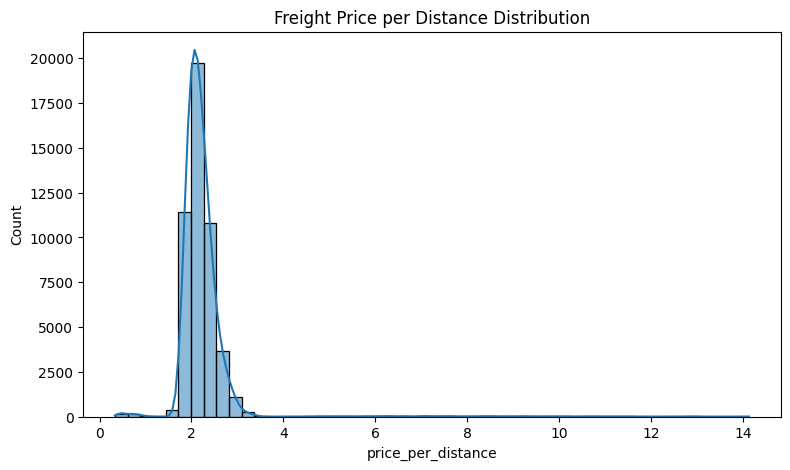

In [15]:
train["price_per_distance"] = (
    train["posted_rate"] / train["distance"]
)

plt.figure(figsize=(9, 5))

sns.histplot(
    train["price_per_distance"],
    bins=50,
    kde=True
)

plt.title("Freight Price per Distance Distribution")
plt.show()

In [16]:
train["route"] = (
    train["pickup"] + " -> " + train["delivery"]
)

route_analysis = (
    train.groupby("route")
    .agg(
        total_loads=("posted_rate", "count"),
        average_price=("posted_rate", "mean"),
        median_price=("posted_rate", "median"),
        average_distance=("distance", "mean")
    )
    .sort_values("total_loads", ascending=False)
)

display(route_analysis.head(20))

,total_loads,average_price,median_price,average_distance
route,,,,
Lexington -> Atlanta,39,560.106154,553.630,208.943590
Phoenix -> Shreveport,39,3507.618462,3554.430,1668.494872
Columbia -> Oklahoma City,39,2330.734615,2327.430,1061.415385
Fort Wayne -> Philadelphia,38,1681.032632,1708.835,791.602632
Fort Wayne -> Hartford,37,1938.657297,1725.990,832.602703
Lexington -> Cincinnati,37,396.691892,377.100,133.327027
Shreveport -> Hartford,37,2867.768108,2812.520,1433.270270
Richmond -> Phoenix,37,5190.194595,5010.880,2705.283784
Lexington -> Kansas City,37,1042.474595,1029.800,447.886486


In [17]:
display(
    train.groupby(train["weight"] < 0)["posted_rate"]
    .agg(["count", "mean", "median", "std"])
)

,count,mean,median,std
weight,,,,
False,47708,2373.883943,2031.16,1485.511426
True,292,2389.786233,1994.96,1641.761285


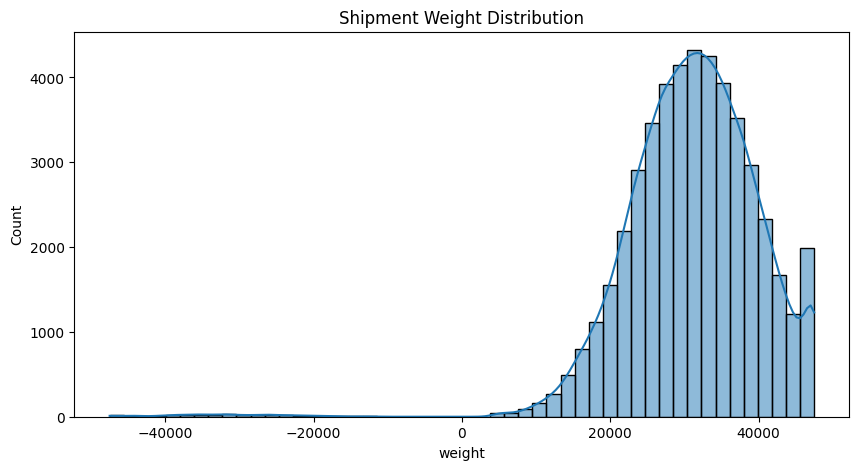

In [18]:
plt.figure(figsize=(10, 5))

sns.histplot(
    train["weight"].dropna(),
    bins=50,
    kde=True
)

plt.title("Shipment Weight Distribution")
plt.show()

In [19]:
print("Negative weights in validation:",
      (validation["weight"] < 0).sum())

print("Missing weights in validation:",
      validation["weight"].isna().sum())

Negative weights in validation: 145
Missing weights in validation: 165


In [20]:
display(
    train.groupby("equipment")["price_per_distance"]
    .agg(["mean", "median", "std"])
)

,mean,median,std
equipment,,,
Dry Van,2.115401,2.046203,0.538102
Flatbed,2.294729,2.219683,0.610187
Reefer,2.383376,2.311540,0.615467


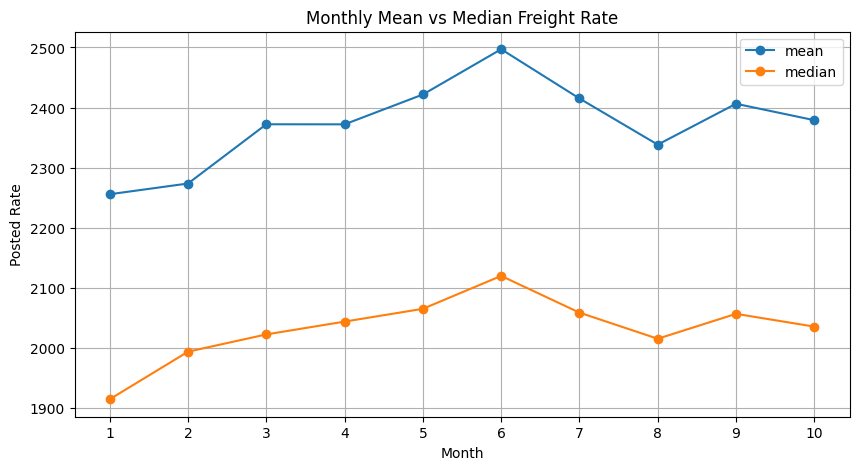

In [21]:
monthly_comparison = (
    train.groupby(train["date"].dt.month)["posted_rate"]
    .agg(["mean", "median"])
)

monthly_comparison.plot(
    figsize=(10, 5),
    marker="o"
)

plt.title("Monthly Mean vs Median Freight Rate")
plt.xlabel("Month")
plt.ylabel("Posted Rate")
plt.xticks(range(1, 11))
plt.grid()
plt.show()

In [22]:
# Classify shipment weights into three categories

train["weight_status"] = np.select(
    [
        train["weight"].isna(),
        train["weight"] < 0
    ],
    [
        "Missing",
        "Negative"
    ],
    default="Valid"
)

# Compare freight prices across the three categories

weight_analysis = (
    train.groupby("weight_status")
    .agg(
        record_count=("load_id", "count"),
        average_price=("posted_rate", "mean"),
        median_price=("posted_rate", "median"),
        std_price=("posted_rate", "std")
    )
    .round(2)
)

display(weight_analysis)

,record_count,average_price,median_price,std_price
weight_status,,,,
Missing,300,2350.67,1985.00,1390.97
Negative,292,2389.79,1994.96,1641.76
Valid,47408,2374.03,2031.44,1486.10


In [23]:
# Preserve the original datasets
train_model = train.copy()
validation_model = validation.copy()
december_model = december.copy()

print("Training:", train_model.shape)
print("Validation:", validation_model.shape)
print("December:", december_model.shape)

Training: (48000, 17)
Validation: (12000, 13)
December: (31, 7)


In [24]:
for name, df in [
    ("Training", train_model),
    ("Validation", validation_model),
    ("December", december_model)
]:
    print(f"\n{name} dataset")
    if "weight" in df.columns:
        print("Negative weights:", (df["weight"] < 0).sum())
        print("Zero weights:", (df["weight"] == 0).sum())
        print("Missing weights:", df["weight"].isna().sum())


Training dataset
Negative weights: 292
Zero weights: 0
Missing weights: 300

Validation dataset
Negative weights: 145
Zero weights: 0
Missing weights: 165

December dataset
Negative weights: 0
Zero weights: 0
Missing weights: 0


In [25]:
for df in [train_model, validation_model, december_model]:

    # Identify negative weights before modifying them
    df["weight_was_negative"] = (
        df["weight"] < 0
    ).astype(int)

    # Identify genuinely missing weights
    df["weight_was_missing"] = (
        df["weight"].isna()
    ).astype(int)

    # Negative weights are invalid
    df.loc[df["weight"] < 0, "weight"] = np.nan

    # Missing market index indicator
    if "market_index" in df.columns:
        df["market_index_missing"] = (
            df["market_index"].isna()
        ).astype(int)

In [26]:
for df in [train_model, validation_model, december_model]:

    df["date"] = pd.to_datetime(df["date"])

    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month
    df["day"] = df["date"].dt.day
    df["day_of_week"] = df["date"].dt.dayofweek
    df["day_of_year"] = df["date"].dt.dayofyear

    df["is_weekend"] = (
        df["day_of_week"] >= 5
    ).astype(int)

In [27]:
for df in [train_model, validation_model, december_model]:

    df["route"] = (
        df["pickup"].astype(str)
        + " -> "
        + df["delivery"].astype(str)
    )

In [28]:
print("Training:", train_model.shape)
print("Validation:", validation_model.shape)
print("December:", december_model.shape)

print("\nRemaining negative training weights:",
      (train_model["weight"] < 0).sum())

print("Remaining negative validation weights:",
      (validation_model["weight"] < 0).sum())

print("\nTraining missing values:")
display(train_model.isnull().sum())

Training: (48000, 26)
Validation: (12000, 23)
December: (31, 16)

Remaining negative training weights: 0
Remaining negative validation weights: 0

Training missing values:


load_id                   0
pickup                    0
delivery                  0
pickup_lat                0
pickup_lon                0
delivery_lat              0
delivery_lon              0
distance                  0
equipment                 0
weight                  592
date                      0
market_index            374
quote_signal              0
posted_rate               0
price_per_distance        0
route                     0
weight_status             0
weight_was_negative       0
weight_was_missing        0
market_index_missing      0
year                      0
month                     0
day                       0
day_of_week               0
day_of_year               0
is_weekend                0
dtype: int64

In [29]:
# Remove EDA-only columns
columns_to_drop = [
    "price_per_distance",
    "weight_status"
]

for df in [train_model, validation_model, december_model]:
    df.drop(
        columns=columns_to_drop,
        errors="ignore",
        inplace=True
    )

print("Training shape:", train_model.shape)
print("Validation shape:", validation_model.shape)
print("December shape:", december_model.shape)

Training shape: (48000, 24)
Validation shape: (12000, 23)
December shape: (31, 16)


In [30]:
# Columns that should not be used as model features
excluded_columns = [
    "load_id",
    "posted_rate",
    "date"
]

# Select input features
feature_cols = [
    col for col in train_model.columns
    if col not in excluded_columns
]

# Separate X and y
X = train_model[feature_cols].copy()
y = train_model["posted_rate"].copy()

print("Number of input features:", len(feature_cols))
print("\nFeatures:")
print(feature_cols)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Number of input features: 21

Features:
['pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'market_index', 'quote_signal', 'route', 'weight_was_negative', 'weight_was_missing', 'market_index_missing', 'year', 'month', 'day', 'day_of_week', 'day_of_year', 'is_weekend']

X shape: (48000, 21)
y shape: (48000,)


In [32]:
from sklearn.model_selection import train_test_split

X_train_random, X_valid_random, y_train_random, y_valid_random = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Random Split Results")
print("--------------------")
print("Training records:", X_train_random.shape[0])
print("Validation records:", X_valid_random.shape[0])

Random Split Results
--------------------
Training records: 38400
Validation records: 9600


In [33]:
# Define cutoff date
cutoff_date = pd.Timestamp("2025-09-01")

# Create chronological masks
train_mask = train_model["date"] < cutoff_date
valid_mask = train_model["date"] >= cutoff_date

# Split input features
X_train_time = X.loc[train_mask].copy()
X_valid_time = X.loc[valid_mask].copy()

# Split target
y_train_time = y.loc[train_mask].copy()
y_valid_time = y.loc[valid_mask].copy()

print("Chronological Split Results")
print("---------------------------")

print("Training records:", len(X_train_time))
print("Validation records:", len(X_valid_time))

print("\nTraining date range:")
print(
    train_model.loc[train_mask, "date"].min(),
    "to",
    train_model.loc[train_mask, "date"].max()
)

print("\nValidation date range:")
print(
    train_model.loc[valid_mask, "date"].min(),
    "to",
    train_model.loc[valid_mask, "date"].max()
)

Chronological Split Results
---------------------------
Training records: 38477
Validation records: 9523

Training date range:
2025-01-01 00:00:00 to 2025-08-31 00:00:00

Validation date range:
2025-09-01 00:00:00 to 2025-10-31 00:00:00


In [34]:
print("RANDOM SPLIT")
print("Training:", len(X_train_random))
print("Validation:", len(X_valid_random))

print("\nCHRONOLOGICAL SPLIT")
print("Training:", len(X_train_time))
print("Validation:", len(X_valid_time))

# Check that no rows are lost
assert len(X_train_random) + len(X_valid_random) == len(train_model)

assert len(X_train_time) + len(X_valid_time) == len(train_model)

# Check chronological ordering
assert train_model.loc[train_mask, "date"].max() < (
    train_model.loc[valid_mask, "date"].min()
)

print("\nAll split checks passed!")

RANDOM SPLIT
Training: 38400
Validation: 9600

CHRONOLOGICAL SPLIT
Training: 38477
Validation: 9523

All split checks passed!


In [35]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Baseline model
baseline = DummyRegressor(strategy="mean")

# Train using chronological training data
baseline.fit(X_train_time, y_train_time)

# Predict September-October prices
baseline_predictions = baseline.predict(X_valid_time)

# Evaluate
baseline_mae = mean_absolute_error(
    y_valid_time, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_valid_time, baseline_predictions)
)

baseline_r2 = r2_score(
    y_valid_time, baseline_predictions
)

print("Baseline Model Performance")
print("--------------------------")
print("MAE:", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))
print("R2:", round(baseline_r2, 4))

Baseline Model Performance
--------------------------
MAE: 1178.8
RMSE: 1526.23
R2: -0.0002


In [36]:
categorical_features = X_train_time.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical features:", categorical_features)

Categorical features: ['pickup', 'delivery', 'equipment', 'route']


In [37]:
# CatBoost expects categorical values as strings
for col in categorical_features:

    X_train_time[col] = (
        X_train_time[col].fillna("Missing").astype(str)
    )

    X_valid_time[col] = (
        X_valid_time[col].fillna("Missing").astype(str)
    )

In [43]:
from catboost import CatBoostRegressor

cat_model = CatBoostRegressor(
    iterations=1500,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    eval_metric="MAE",
    random_seed=42
)

cat_model.fit(
    X_train_time,
    y_train_time,
    cat_features=categorical_features,
    eval_set=(X_valid_time, y_valid_time),
    early_stopping_rounds=100,
    verbose=200
)

0:	learn: 1104.3152738	test: 1126.2156447	best: 1126.2156447 (0)	total: 56.4ms	remaining: 1m 24s
200:	learn: 103.4615115	test: 114.7023531	best: 113.9046338 (136)	total: 16.7s	remaining: 1m 48s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 113.9046338
bestIteration = 136

Shrink model to first 137 iterations.


CatBoostRegressor(depth=8, eval_metric='MAE', iterations=1500, learning_rate=0.05, loss_function='RMSE', random_seed=42)

In [44]:
cat_predictions = cat_model.predict(X_valid_time)

cat_mae = mean_absolute_error(
    y_valid_time, cat_predictions
)

cat_rmse = np.sqrt(
    mean_squared_error(y_valid_time, cat_predictions)
)

cat_r2 = r2_score(
    y_valid_time, cat_predictions
)

print("CatBoost Performance")
print("--------------------")
print("MAE:", round(cat_mae, 2))
print("RMSE:", round(cat_rmse, 2))
print("R2:", round(cat_r2, 4))

CatBoost Performance
--------------------
MAE: 113.9
RMSE: 633.68
R2: 0.8276


In [45]:
results = pd.DataFrame({
    "Model": ["Mean Baseline", "CatBoost"],
    "MAE": [baseline_mae, cat_mae],
    "RMSE": [baseline_rmse, cat_rmse],
    "R2": [baseline_r2, cat_r2]
})

display(results.round(4))

,Model,MAE,RMSE,R2
0,Mean Baseline,1178.8033,1526.2263,-0.0002
1,CatBoost,113.9046,633.6758,0.8276


In [42]:
# Rebuild everything AFTER sorting

train_sorted = (
    train_model
    .sort_values("date")
    .reset_index(drop=True)
)

excluded_columns = ["load_id", "posted_rate", "date"]

feature_cols = [
    col for col in train_sorted.columns
    if col not in excluded_columns
]

X_sorted = train_sorted[feature_cols].copy()
y_sorted = train_sorted["posted_rate"].copy()

# Chronological split
train_mask = train_sorted["date"] < "2025-09-01"

X_train_time = X_sorted.loc[train_mask].copy()
X_valid_time = X_sorted.loc[~train_mask].copy()

y_train_time = y_sorted.loc[train_mask].copy()
y_valid_time = y_sorted.loc[~train_mask].copy()

print("Training:", X_train_time.shape)
print("Validation:", X_valid_time.shape)

# Verify row alignment
assert X_train_time.index.equals(y_train_time.index)
assert X_valid_time.index.equals(y_valid_time.index)

print("Feature-target alignment verified!")

Training: (38477, 21)
Validation: (9523, 21)
Feature-target alignment verified!


In [46]:
predictions = cat_model.predict(X_valid_time)

error_analysis = pd.DataFrame({
    "Actual": y_valid_time,
    "Predicted": predictions
})

error_analysis["Absolute_Error"] = (
    error_analysis["Actual"] - error_analysis["Predicted"]
).abs()

display(
    error_analysis
    .sort_values("Absolute_Error", ascending=False)
    .head(15)
)

,Actual,Predicted,Absolute_Error
40156,20132.37,3791.391532,16340.978468
40071,20361.89,4391.294920,15970.595080
43605,17514.11,3673.412184,13840.697816
46279,17893.17,4166.439639,13726.730361
47204,19110.30,5891.505513,13218.794487
40220,14949.25,3278.248614,11671.001386
46608,14784.38,3601.799836,11182.580164
42941,13503.63,2960.531025,10543.098975
42247,13026.22,2818.735152,10207.484848
46444,14403.14,4282.495876,10120.644124


In [47]:
error_analysis = pd.DataFrame({
    "Actual": y_valid_time.to_numpy(),
    "Predicted": predictions
})

error_analysis["Absolute_Error"] = (
    error_analysis["Actual"] - error_analysis["Predicted"]
).abs()

display(
    error_analysis
    .sort_values("Absolute_Error", ascending=False)
    .head(15)
)

,Actual,Predicted,Absolute_Error
1679,20132.37,3791.391532,16340.978468
1594,20361.89,4391.294920,15970.595080
5128,17514.11,3673.412184,13840.697816
7802,17893.17,4166.439639,13726.730361
8727,19110.30,5891.505513,13218.794487
1743,14949.25,3278.248614,11671.001386
8131,14784.38,3601.799836,11182.580164
4464,13503.63,2960.531025,10543.098975
3770,13026.22,2818.735152,10207.484848
7967,14403.14,4282.495876,10120.644124


In [48]:
# Generate fresh predictions from the current model
fresh_predictions = cat_model.predict(X_valid_time)

# Check lengths and index alignment
print("X validation rows:", len(X_valid_time))
print("Y validation rows:", len(y_valid_time))
print("Prediction rows:", len(fresh_predictions))

print(
    "Feature-target indices aligned:",
    X_valid_time.index.equals(y_valid_time.index)
)

# Compare the first 5 rows manually
check = pd.DataFrame({
    "Actual": y_valid_time.to_numpy()[:5],
    "Predicted": fresh_predictions[:5]
})

check["Calculated_Error"] = (
    check["Actual"] - check["Predicted"]
).abs()

display(check)

X validation rows: 9523
Y validation rows: 9523
Prediction rows: 9523
Feature-target indices aligned: True


,Actual,Predicted,Calculated_Error
0,2990.87,3109.166320,118.296320
1,1797.48,1772.085740,25.394260
2,1255.91,1277.906806,21.996806
3,3678.91,3734.505567,55.595567
4,1959.31,1963.549093,4.239093


In [49]:
error_analysis = pd.DataFrame({
    "Actual": y_valid_time.to_numpy(),
    "Predicted": fresh_predictions
})

error_analysis["Absolute_Error"] = (
    error_analysis["Actual"] - error_analysis["Predicted"]
).abs()

display(
    error_analysis
    .sort_values("Absolute_Error", ascending=False)
    .head(15)
)

,Actual,Predicted,Absolute_Error
1679,20132.37,3791.391532,16340.978468
1594,20361.89,4391.294920,15970.595080
5128,17514.11,3673.412184,13840.697816
7802,17893.17,4166.439639,13726.730361
8727,19110.30,5891.505513,13218.794487
1743,14949.25,3278.248614,11671.001386
8131,14784.38,3601.799836,11182.580164
4464,13503.63,2960.531025,10543.098975
3770,13026.22,2818.735152,10207.484848
7967,14403.14,4282.495876,10120.644124


In [50]:
print(error_analysis.head(3).to_string(index=False))

print("\nRecalculating errors:")
print(
    (
        error_analysis["Actual"] -
        error_analysis["Predicted"]
    ).abs().head(3).to_string(index=False)
)

 Actual   Predicted  Absolute_Error
2990.87 3109.166320      118.296320
1797.48 1772.085740       25.394260
1255.91 1277.906806       21.996806

Recalculating errors:
118.296320
 25.394260
 21.996806


In [51]:
display(
    error_analysis
    .sort_values("Absolute_Error", ascending=False)
    .head(15)
)

,Actual,Predicted,Absolute_Error
1679,20132.37,3791.391532,16340.978468
1594,20361.89,4391.294920,15970.595080
5128,17514.11,3673.412184,13840.697816
7802,17893.17,4166.439639,13726.730361
8727,19110.30,5891.505513,13218.794487
1743,14949.25,3278.248614,11671.001386
8131,14784.38,3601.799836,11182.580164
4464,13503.63,2960.531025,10543.098975
3770,13026.22,2818.735152,10207.484848
7967,14403.14,4282.495876,10120.644124


In [52]:
worst_15 = error_analysis.nlargest(15, "Absolute_Error")

for row in worst_15.itertuples(index=False):
    print(
        f"Actual: {row.Actual:.2f} | "
        f"Predicted: {row.Predicted:.2f} | "
        f"Error: {row.Absolute_Error:.2f}"
    )

Actual: 20132.37 | Predicted: 3791.39 | Error: 16340.98
Actual: 20361.89 | Predicted: 4391.29 | Error: 15970.60
Actual: 17514.11 | Predicted: 3673.41 | Error: 13840.70
Actual: 17893.17 | Predicted: 4166.44 | Error: 13726.73
Actual: 19110.30 | Predicted: 5891.51 | Error: 13218.79
Actual: 14949.25 | Predicted: 3278.25 | Error: 11671.00
Actual: 14784.38 | Predicted: 3601.80 | Error: 11182.58
Actual: 13503.63 | Predicted: 2960.53 | Error: 10543.10
Actual: 13026.22 | Predicted: 2818.74 | Error: 10207.48
Actual: 14403.14 | Predicted: 4282.50 | Error: 10120.64
Actual: 15003.55 | Predicted: 5027.27 | Error: 9976.28
Actual: 14425.42 | Predicted: 4512.83 | Error: 9912.59
Actual: 13894.55 | Predicted: 4447.72 | Error: 9446.83
Actual: 11696.44 | Predicted: 2301.10 | Error: 9395.34
Actual: 12797.54 | Predicted: 3597.47 | Error: 9200.07


In [53]:
worst_indices = error_analysis.nlargest(
    15, "Absolute_Error"
).index

worst_loads = train_sorted.loc[
    worst_indices,
    feature_cols + ["posted_rate"]
].copy()

worst_loads["Predicted"] = fresh_predictions[
    error_analysis["Absolute_Error"]
    .nlargest(15)
    .index
]

display(worst_loads)

,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,market_index,...,weight_was_missing,market_index_missing,year,month,day,day_of_week,day_of_year,is_weekend,posted_rate,Predicted
1679,Baltimore,Phoenix,38.16908,-72.74564,28.75668,-115.87725,2939.2,Dry Van,25679.0,0.85723,...,0,0,2025,1,11,5,11,1,4885.24,3791.391532
1594,Albany,Dayton,43.96975,-71.05842,39.87206,-85.62931,950.9,Reefer,18615.0,0.96883,...,0,0,2025,1,10,4,10,0,1945.92,4391.294920
5128,Dallas,Chattanooga,31.83025,-94.38343,35.29792,-87.18651,593.6,Dry Van,34319.0,0.84416,...,0,0,2025,2,2,6,33,1,1240.67,3673.412184
7802,Syracuse,Jacksonville,42.80915,-76.89973,31.98691,-84.48897,1017.8,Dry Van,28449.0,1.08950,...,0,0,2025,2,19,2,50,0,1949.57,4166.439639
8727,Baltimore,Houston,38.16908,-72.74564,30.71157,-94.76550,1577.5,Dry Van,36526.0,1.02898,...,0,0,2025,2,25,1,56,0,3077.35,5891.505513
1743,Reno,Greensboro,39.54838,-118.64843,35.98195,-82.78379,2233.5,Dry Van,37580.0,0.91546,...,0,0,2025,1,11,5,11,1,3959.51,3278.248614
8131,Houston,Richmond,30.71157,-94.76550,38.09122,-76.78906,1356.5,Dry Van,46911.0,1.05398,...,0,0,2025,2,21,4,52,0,2676.69,3601.799836
4464,San Antonio,Kansas City,29.50969,-98.40059,39.41104,-91.12450,944.8,Dry Van,23244.0,1.04645,...,0,0,2025,1,29,2,29,0,1896.62,2960.531025
3770,Richmond,Dayton,38.09122,-76.78906,39.87206,-85.62931,566.8,Reefer,43997.0,0.93060,...,0,0,2025,1,24,4,24,0,1311.20,2818.735152
7967,Philadelphia,Birmingham,39.22317,-72.96710,33.45794,-86.72789,998.1,Dry Van,24173.0,1.11160,...,0,0,2025,2,20,3,51,0,1862.01,4282.495876


In [54]:
coordinate_cols = [
    "pickup_lat", "pickup_lon",
    "delivery_lat", "delivery_lon"
]

display(train_model[coordinate_cols].describe())

,pickup_lat,pickup_lon,delivery_lat,delivery_lon
count,48000.000000,48000.000000,48000.000000,48000.000000
mean,35.647545,-90.928964,35.641175,-90.857310
std,4.315285,13.482431,4.317199,13.476589
min,28.357650,-121.698490,28.357650,-121.698490
25%,31.986910,-98.400590,31.986910,-98.400590
50%,35.294790,-88.089150,35.294790,-87.528710
75%,39.411040,-83.285060,39.411040,-83.285060
max,44.302960,-69.500000,44.302960,-69.500000


In [55]:
display(
    train_model[
        (train_model["pickup_lat"].abs() > 90) |
        (train_model["delivery_lat"].abs() > 90) |
        (train_model["pickup_lon"].abs() > 180) |
        (train_model["delivery_lon"].abs() > 180)
    ][coordinate_cols].head(10)
)

,pickup_lat,pickup_lon,delivery_lat,delivery_lon


In [56]:
error_analysis["Rate_Range"] = pd.cut(
    error_analysis["Actual"],
    bins=[0, 1000, 2000, 4000, 7000, 10000, float("inf")],
    labels=["0-1000", "1000-2000", "2000-4000",
            "4000-7000", "7000-10000", "10000+"]
)

display(
    error_analysis.groupby("Rate_Range", observed=True)
    .agg(
        Count=("Actual", "count"),
        MAE=("Absolute_Error", "mean"),
        Average_Actual=("Actual", "mean"),
        Average_Predicted=("Predicted", "mean")
    )
)

,Count,MAE,Average_Actual,Average_Predicted
Rate_Range,,,,
0-1000,1545,81.075513,697.316311,758.220414
1000-2000,3077,47.583848,1482.622294,1480.835363
2000-4000,3387,69.910619,2845.516519,2836.957095
4000-7000,1473,160.513726,4770.806972,4684.724321
7000-10000,17,5508.657253,8392.646471,2883.989218
10000+,24,10256.896827,14003.431250,3746.534423


In [57]:
from catboost import CatBoostRegressor
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Transform target
y_train_log = np.log1p(y_train_time)
y_valid_log = np.log1p(y_valid_time)

# Create model
cat_log_model = CatBoostRegressor(
    iterations=1500,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    random_seed=42,
    verbose=200
)

# Train
cat_log_model.fit(
    X_train_time,
    y_train_log,
    cat_features=categorical_features,
    eval_set=(X_valid_time, y_valid_log),
    early_stopping_rounds=100
)

# Predict and convert back
log_predictions = cat_log_model.predict(X_valid_time)
log_predictions = np.expm1(log_predictions)

# Evaluate
print("Log CatBoost MAE:",
      mean_absolute_error(y_valid_time, log_predictions))

print("Log CatBoost RMSE:",
      np.sqrt(mean_squared_error(y_valid_time, log_predictions)))

print("Log CatBoost R2:",
      r2_score(y_valid_time, log_predictions))

0:	learn: 0.6358436	test: 0.6442331	best: 0.6442331 (0)	total: 64.4ms	remaining: 1m 36s
200:	learn: 0.1490765	test: 0.1608842	best: 0.1608648 (195)	total: 19.3s	remaining: 2m 4s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.1608389201
bestIteration = 219

Shrink model to first 220 iterations.
Log CatBoost MAE: 113.5559560779907
Log CatBoost RMSE: 635.4788389452992
Log CatBoost R2: 0.8265943234641786


In [59]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prepare copies
X_train_xgb = X_train_time.copy()
X_valid_xgb = X_valid_time.copy()

# Convert categorical columns to category dtype
for col in categorical_features:
    X_train_xgb[col] = X_train_xgb[col].fillna("Missing").astype("category")
    X_valid_xgb[col] = X_valid_xgb[col].fillna("Missing").astype("category")

# Create model
xgb_model = XGBRegressor(
    n_estimators=1500,
    learning_rate=0.05,
    max_depth=8,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="mae",
    enable_categorical=True,
    early_stopping_rounds=100,
    random_state=42,
    n_jobs=-1
)

# Train
xgb_model.fit(
    X_train_xgb,
    y_train_time,
    eval_set=[(X_valid_xgb, y_valid_time)],
    verbose=200
)

# Predict
xgb_predictions = xgb_model.predict(X_valid_xgb)

# Evaluate
print("XGBoost MAE:", mean_absolute_error(y_valid_time, xgb_predictions))
print("XGBoost RMSE:", mean_squared_error(y_valid_time, xgb_predictions) ** 0.5)
print("XGBoost R2:", r2_score(y_valid_time, xgb_predictions))

[0]	validation_0-mae:1124.11894
[192]	validation_0-mae:171.44983
XGBoost MAE: 163.90053364569556
XGBoost RMSE: 663.6766237425642
XGBoost R2: 0.8108640150018221


,Feature,Importance
6,distance,87.923199
7,equipment,4.203633
8,weight,1.324736
9,market_index,1.157274
19,day_of_year,0.857019
16,month,0.805290
10,quote_signal,0.550750
4,delivery_lat,0.526280
0,pickup,0.491434
2,pickup_lat,0.450945


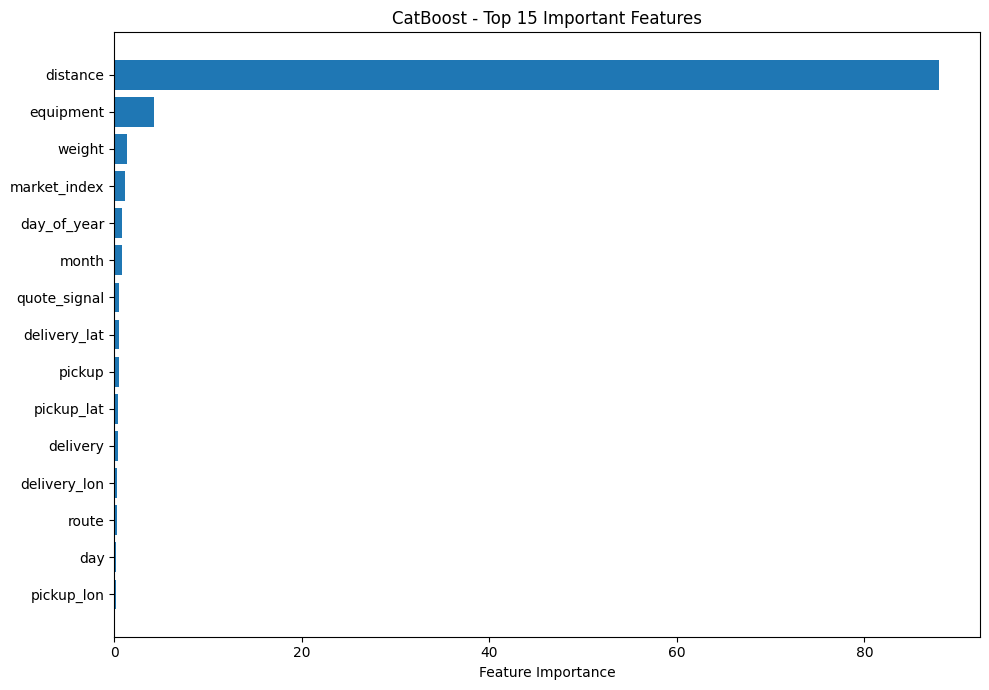

In [60]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "Feature": X_train_time.columns,
    "Importance": cat_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance", ascending=False
)

display(feature_importance)

plt.figure(figsize=(10, 7))
plt.barh(
    feature_importance["Feature"].head(15),
    feature_importance["Importance"].head(15)
)
plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.title("CatBoost - Top 15 Important Features")
plt.tight_layout()
plt.show()

In [61]:
for df in [train_model, validation_model, december_model]:

    df["distance_squared"] = df["distance"] ** 2

    df["distance_per_weight"] = (
        df["distance"] /
        df["weight"].replace(0, np.nan)
    )

In [62]:
# Sort data chronologically
train_sorted = train_model.sort_values("date").reset_index(drop=True)

# Exclude identifiers, target, raw date and EDA-only columns
excluded_columns = [
    "load_id",
    "posted_rate",
    "date",
    "price_per_distance",
    "weight_status"
]

feature_cols = [
    col for col in train_sorted.columns
    if col not in excluded_columns
]

# Build features and target
X_sorted = train_sorted[feature_cols].copy()
y_sorted = train_sorted["posted_rate"].copy()

# Chronological split: train before September, validate September onward
train_mask = train_sorted["date"] < "2025-09-01"

X_train_time = X_sorted.loc[train_mask].copy()
X_valid_time = X_sorted.loc[~train_mask].copy()

y_train_time = y_sorted.loc[train_mask].copy()
y_valid_time = y_sorted.loc[~train_mask].copy()

# Identify categorical features
categorical_features = (
    X_train_time.select_dtypes(include=["object", "category"])
    .columns.tolist()
)

# Handle categorical missing values
for col in categorical_features:
    X_train_time[col] = (
        X_train_time[col].fillna("Missing").astype(str)
    )
    X_valid_time[col] = (
        X_valid_time[col].fillna("Missing").astype(str)
    )

print("Training rows:", len(X_train_time))
print("Validation rows:", len(X_valid_time))
print("Features:", len(feature_cols))
print("New features:", [
    "distance_squared", "distance_per_weight"
])

assert X_train_time.index.equals(y_train_time.index)
assert X_valid_time.index.equals(y_valid_time.index)

Training rows: 38477
Validation rows: 9523
Features: 23
New features: ['distance_squared', 'distance_per_weight']


In [63]:
cat_engineered = CatBoostRegressor(
    iterations=1500,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    eval_metric="MAE",
    random_seed=42,
    verbose=200
)

cat_engineered.fit(
    X_train_time,
    y_train_time,
    cat_features=categorical_features,
    eval_set=(X_valid_time, y_valid_time),
    early_stopping_rounds=100
)

0:	learn: 1101.8256866	test: 1123.5461273	best: 1123.5461273 (0)	total: 83.9ms	remaining: 2m 5s
200:	learn: 102.5357192	test: 109.5673619	best: 109.2868103 (185)	total: 21.9s	remaining: 2m 21s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 109.2419272
bestIteration = 234

Shrink model to first 235 iterations.


CatBoostRegressor(depth=8, eval_metric='MAE', iterations=1500, learning_rate=0.05, loss_function='RMSE', random_seed=42, verbose=200)

In [64]:
engineered_predictions = cat_engineered.predict(X_valid_time)

print(
    "Engineered CatBoost MAE:",
    mean_absolute_error(y_valid_time, engineered_predictions)
)

print(
    "Engineered CatBoost RMSE:",
    np.sqrt(mean_squared_error(y_valid_time, engineered_predictions))
)

print(
    "Engineered CatBoost R2:",
    r2_score(y_valid_time, engineered_predictions)
)

Engineered CatBoost MAE: 109.24192991090945
Engineered CatBoost RMSE: 633.0680209930086
Engineered CatBoost R2: 0.8279075270347874


In [65]:
engineered_importance = pd.DataFrame({
    "Feature": X_train_time.columns,
    "Importance": cat_engineered.feature_importances_
})

display(
    engineered_importance.sort_values(
        "Importance", ascending=False
    )
)

,Feature,Importance
21,distance_squared,49.682440
6,distance,31.857045
7,equipment,5.232458
8,weight,2.060891
9,market_index,1.856417
22,distance_per_weight,1.525363
19,day_of_year,1.195667
10,quote_signal,1.004105
16,month,0.978321
0,pickup,0.885218


In [66]:
# Features available in the December template
december_feature_cols = [
    "pickup",
    "delivery",
    "distance",
    "equipment",
    "weight",
    "weight_was_negative",
    "weight_was_missing",
    "route",
    "year",
    "month",
    "day",
    "day_of_week",
    "day_of_year",
    "is_weekend",
    "distance_squared",
    "distance_per_weight"
]

# Build datasets using exactly the same features
X_dec_train = train_model[december_feature_cols].copy()
X_dec_valid = validation_model[december_feature_cols].copy()
X_december = december_model[december_feature_cols].copy()

y_dec_train = train_model["posted_rate"].copy()

# Chronological training split
train_mask_dec = train_model["date"] < "2025-09-01"

X_dec_train_part = X_dec_train.loc[train_mask_dec].copy()
X_dec_valid_part = X_dec_train.loc[~train_mask_dec].copy()

y_dec_train_part = y_dec_train.loc[train_mask_dec].copy()
y_dec_valid_part = y_dec_train.loc[~train_mask_dec].copy()

# Identify categorical columns
categorical_dec = (
    X_dec_train_part
    .select_dtypes(include=["object", "category"])
    .columns.tolist()
)

# Handle categorical values consistently
for df in [
    X_dec_train_part,
    X_dec_valid_part,
    X_dec_valid,
    X_december
]:
    for col in categorical_dec:
        df[col] = df[col].fillna("Missing").astype(str)

print("Training:", X_dec_train_part.shape)
print("Validation:", X_dec_valid_part.shape)
print("December:", X_december.shape)
print("Features:", december_feature_cols)

Training: (38477, 16)
Validation: (9523, 16)
December: (31, 16)
Features: ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'weight_was_negative', 'weight_was_missing', 'route', 'year', 'month', 'day', 'day_of_week', 'day_of_year', 'is_weekend', 'distance_squared', 'distance_per_weight']


In [67]:
cat_december = CatBoostRegressor(
    iterations=1500,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    eval_metric="MAE",
    random_seed=42,
    verbose=200
)

cat_december.fit(
    X_dec_train_part,
    y_dec_train_part,
    cat_features=categorical_dec,
    eval_set=(X_dec_valid_part, y_dec_valid_part),
    early_stopping_rounds=100
)

0:	learn: 1103.9577681	test: 1125.6971533	best: 1125.6971533 (0)	total: 74.6ms	remaining: 1m 51s
200:	learn: 113.0964258	test: 123.5287736	best: 122.9862195 (166)	total: 19s	remaining: 2m 3s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 122.9862195
bestIteration = 166

Shrink model to first 167 iterations.


CatBoostRegressor(depth=8, eval_metric='MAE', iterations=1500, learning_rate=0.05, loss_function='RMSE', random_seed=42, verbose=200)

In [68]:
dec_valid_predictions = cat_december.predict(
    X_dec_valid_part
)

print(
    "December-compatible MAE:",
    mean_absolute_error(
        y_dec_valid_part, dec_valid_predictions
    )
)

print(
    "December-compatible RMSE:",
    np.sqrt(mean_squared_error(
        y_dec_valid_part, dec_valid_predictions
    ))
)

print(
    "December-compatible R2:",
    r2_score(
        y_dec_valid_part, dec_valid_predictions
    )
)

December-compatible MAE: 122.98622168331383
December-compatible RMSE: 633.4106420968868
December-compatible R2: 0.8277212011848782


In [69]:
common_features = [
    "pickup",
    "delivery",
    "distance",
    "equipment",
    "weight",
    "weight_was_negative",
    "weight_was_missing",
    "route",
    "year",
    "month",
    "day",
    "day_of_week",
    "day_of_year",
    "is_weekend",
    "distance_squared",
    "distance_per_weight"
]

# Sort training data chronologically
train_common = train_model.sort_values(
    "date"
).reset_index(drop=True)

# Create feature matrix and target
X_common = train_common[common_features].copy()
y_common = train_common["posted_rate"].copy()

# Chronological split
train_mask = train_common["date"] < "2025-09-01"

X_train_common = X_common.loc[train_mask].copy()
X_valid_common = X_common.loc[~train_mask].copy()

y_train_common = y_common.loc[train_mask].copy()
y_valid_common = y_common.loc[~train_mask].copy()

# Identify categorical features
categorical_common = (
    X_train_common.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()
)

# Consistent categorical preprocessing
for col in categorical_common:
    X_train_common[col] = (
        X_train_common[col].fillna("Missing").astype(str)
    )
    X_valid_common[col] = (
        X_valid_common[col].fillna("Missing").astype(str)
    )

print("Training shape:", X_train_common.shape)
print("Validation shape:", X_valid_common.shape)
print("Categorical features:", categorical_common)

assert X_train_common.index.equals(y_train_common.index)
assert X_valid_common.index.equals(y_valid_common.index)

Training shape: (38477, 16)
Validation shape: (9523, 16)
Categorical features: ['pickup', 'delivery', 'equipment', 'route']


In [71]:
common_model = CatBoostRegressor(
    iterations=1500,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    eval_metric="MAE",
    random_seed=42,
    verbose=200
)

common_model.fit(
    X_train_common,
    y_train_common,
    cat_features=categorical_common,
    eval_set=(X_valid_common, y_valid_common),
    early_stopping_rounds=100
)

0:	learn: 1103.9549263	test: 1125.6977797	best: 1125.6977797 (0)	total: 71.9ms	remaining: 1m 47s
200:	learn: 112.9845206	test: 123.2647809	best: 122.5832280 (174)	total: 21.8s	remaining: 2m 21s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 122.583228
bestIteration = 174

Shrink model to first 175 iterations.


CatBoostRegressor(depth=8, eval_metric='MAE', iterations=1500, learning_rate=0.05, loss_function='RMSE', random_seed=42, verbose=200)

In [72]:
common_predictions = common_model.predict(X_valid_common)

print(
    "Common Model MAE:",
    mean_absolute_error(y_valid_common, common_predictions)
)

print(
    "Common Model RMSE:",
    np.sqrt(mean_squared_error(y_valid_common, common_predictions))
)

print(
    "Common Model R2:",
    r2_score(y_valid_common, common_predictions)
)

Common Model MAE: 122.58322930209684
Common Model RMSE: 633.8997484889267
Common Model R2: 0.8274550383229377


In [73]:
# Prepare all training data
X_final = train_common[common_features].copy()
y_final = train_common["posted_rate"].copy()

# Prepare validation data
X_validation_final = validation_model[common_features].copy()

# Prepare December data
X_december_final = december_model[common_features].copy()

# Handle categorical columns consistently
for col in categorical_common:
    for df in [
        X_final,
        X_validation_final,
        X_december_final
    ]:
        df[col] = df[col].fillna("Missing").astype(str)

print("Final training:", X_final.shape)
print("Validation prediction:", X_validation_final.shape)
print("December prediction:", X_december_final.shape)

Final training: (48000, 16)
Validation prediction: (12000, 16)
December prediction: (31, 16)


In [74]:
final_model = CatBoostRegressor(
    iterations=common_model.best_iteration_ + 1,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    random_seed=42,
    verbose=200
)

final_model.fit(
    X_final,
    y_final,
    cat_features=categorical_common
)

0:	learn: 1426.9619559	total: 63.4ms	remaining: 11s
174:	learn: 579.3092421	total: 14.3s	remaining: 0us


CatBoostRegressor(depth=8, iterations=175, learning_rate=0.05, loss_function='RMSE', random_seed=42, verbose=200)

In [75]:
validation_predictions = final_model.predict(X_validation_final)

validation_output = pd.DataFrame({
    "load_id": validation_model["load_id"],
    "predicted_rate": validation_predictions
})

print(validation_output.head())
print("Shape:", validation_output.shape)
print("Missing predictions:", validation_output["predicted_rate"].isna().sum())

     load_id  predicted_rate
0  TE-000001      854.194023
1  TE-000002     4864.331785
2  TE-000003     5555.233428
3  TE-000004     4141.576378
4  TE-000005     1747.049037
Shape: (12000, 2)
Missing predictions: 0


In [76]:
validation_output.to_csv(
    "../validation_predictions.csv",
    index=False
)

print("Validation predictions saved successfully!")

Validation predictions saved successfully!


In [77]:
december_predictions = final_model.predict(X_december_final)

december_output = december_model.copy()

december_output["predicted_rate"] = december_predictions

display(
    december_output[
        ["date", "pickup", "delivery", "predicted_rate"]
    ].head(10)
)

,date,pickup,delivery,predicted_rate
0,2025-12-01,Lexington,Fort Wayne,823.478170
1,2025-12-02,Lexington,Fort Wayne,845.587818
2,2025-12-03,Lexington,Fort Wayne,859.549358
3,2025-12-04,Lexington,Fort Wayne,860.676528
4,2025-12-05,Lexington,Fort Wayne,855.616818
5,2025-12-06,Lexington,Fort Wayne,843.087376
6,2025-12-07,Lexington,Fort Wayne,838.903077
7,2025-12-08,Lexington,Fort Wayne,825.622883
8,2025-12-09,Lexington,Fort Wayne,846.879638
9,2025-12-10,Lexington,Fort Wayne,861.630467


In [78]:
december_output.to_csv(
    "../december_predictions.csv",
    index=False
)

In [80]:
# Create exact seven-column December submission
december_submission = december_model[
    ["pickup", "delivery", "distance",
     "equipment", "weight", "date"]
].copy()

december_submission["predicted_rate"] = december_predictions

# Ensure exact column order
december_submission = december_submission[
    ["pickup", "delivery", "distance",
     "equipment", "weight", "date", "predicted_rate"]
]

# Sort by date
december_submission["date"] = pd.to_datetime(
    december_submission["date"]
)

december_submission = december_submission.sort_values("date")

# Save to the required location
december_submission.to_csv(
    "../data/december_chart_inputs.csv",
    index=False,
    date_format="%Y-%m-%d"
)

display(december_submission)

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000.0,2025-12-01,823.478170
1,Lexington,Fort Wayne,360,Dry Van,32000.0,2025-12-02,845.587818
2,Lexington,Fort Wayne,360,Dry Van,32000.0,2025-12-03,859.549358
3,Lexington,Fort Wayne,360,Dry Van,32000.0,2025-12-04,860.676528
4,Lexington,Fort Wayne,360,Dry Van,32000.0,2025-12-05,855.616818
5,Lexington,Fort Wayne,360,Dry Van,32000.0,2025-12-06,843.087376
6,Lexington,Fort Wayne,360,Dry Van,32000.0,2025-12-07,838.903077
7,Lexington,Fort Wayne,360,Dry Van,32000.0,2025-12-08,825.622883
8,Lexington,Fort Wayne,360,Dry Van,32000.0,2025-12-09,846.879638
9,Lexington,Fort Wayne,360,Dry Van,32000.0,2025-12-10,861.630467


In [82]:
# Create exact seven-column December submission
december_submission = december_model[
    ["pickup", "delivery", "distance",
     "equipment", "weight", "date"]
].copy()

december_submission["predicted_rate"] = december_predictions

# Ensure exact column order
december_submission = december_submission[
    ["pickup", "delivery", "distance",
     "equipment", "weight", "date", "predicted_rate"]
]

# Sort by date
december_submission["date"] = pd.to_datetime(
    december_submission["date"]
)

december_submission = december_submission.sort_values("date")

# Save to the required location
december_submission.to_csv(
    "../data/december_chart_inputs.csv",
    index=False,
    date_format="%Y-%m-%d"
)

display(december_submission)

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000.0,2025-12-01,823.478170
1,Lexington,Fort Wayne,360,Dry Van,32000.0,2025-12-02,845.587818
2,Lexington,Fort Wayne,360,Dry Van,32000.0,2025-12-03,859.549358
3,Lexington,Fort Wayne,360,Dry Van,32000.0,2025-12-04,860.676528
4,Lexington,Fort Wayne,360,Dry Van,32000.0,2025-12-05,855.616818
5,Lexington,Fort Wayne,360,Dry Van,32000.0,2025-12-06,843.087376
6,Lexington,Fort Wayne,360,Dry Van,32000.0,2025-12-07,838.903077
7,Lexington,Fort Wayne,360,Dry Van,32000.0,2025-12-08,825.622883
8,Lexington,Fort Wayne,360,Dry Van,32000.0,2025-12-09,846.879638
9,Lexington,Fort Wayne,360,Dry Van,32000.0,2025-12-10,861.630467


In [83]:
print("Columns:", validation_output.columns.tolist())
print("Rows:", len(validation_output))
print("Duplicate IDs:", validation_output["load_id"].duplicated().sum())
print("Missing predictions:", validation_output["predicted_rate"].isna().sum())
print("Minimum prediction:", validation_output["predicted_rate"].min())

Columns: ['load_id', 'predicted_rate']
Rows: 12000
Duplicate IDs: 0
Missing predictions: 0
Minimum prediction: 263.0102978553359
